# Exploratory Data Analysis of House Prices

## 1. Introduction

The objective of this project is to perform Exploratory Data Analysis (EDA) on the Ames Housing Dataset.

We will analyse house prices, identify important features, study data distributions, detect outliers, and understand relationships between different variables using Python.

In [60]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")


All libraries imported successfully!


Read CSV File

In [61]:

df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


Check dataset shape

In [62]:

print("Number of rows and columns:")
print(df.shape)


Number of rows and columns:
(1460, 81)


Display first five rows

In [63]:

df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Check column information

In [64]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

Check missing values

In [65]:

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print("Columns with missing values:")
print(missing_values.sort_values(ascending=False))


Columns with missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


### Initial Dataset Observations

1. The dataset contains 1460 rows and 81 columns.
2. Each row represents a house sale.
3. The dataset contains numerical and categorical variables.
4. Some columns contain missing values.
5. SalePrice is the target variable that we will analyse throughout the project.

## 4. Variable Classification

In this step, we classify the dataset variables into numerical, categorical and ordinal types.

- Numerical variables contain numbers.
- Categorical variables represent groups or categories.
- Ordinal variables represent categories with a meaningful order.

Separate variables

In [66]:

# Identify numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Identify categorical columns
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Total Numerical Columns:", len(numeric_cols))
print("Total Categorical Columns:", len(categorical_cols))

print("\nNumerical Columns:")
print(numeric_cols)

print("\nCategorical Columns:")
print(categorical_cols)


Total Numerical Columns: 38
Total Categorical Columns: 43

Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'Centra

Define ordinal variables

In [67]:

# Define ordinal categories
ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

# Convert columns into ordered categorical variables
for col in ordinal_map:
    df[col] = pd.Categorical(
        df[col],
        categories=ordinal_map[col],
        ordered=True
    )

print("Ordinal variables converted successfully!")


Ordinal variables converted successfully!


Create a variable summary table

In [68]:

summary = []

for col in df.columns:

    if col in ["OverallQual", "ExterQual", "KitchenQual"]:
        var_type = "Ordinal"

    elif col in numeric_cols:
        var_type = "Numerical"

    else:
        var_type = "Categorical"

    unique_count = df[col].nunique()

    examples = df[col].dropna().unique()[:5]

    summary.append({
        "Column Name": col,
        "Variable Type": var_type,
        "Unique Values": unique_count,
        "Example Values": list(examples)
    })

summary_df = pd.DataFrame(summary)

display(summary_df)


,Column Name,Variable Type,Unique Values,Example Values
0,Id,Numerical,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,Numerical,15,"[60, 20, 70, 50, 190]"
2,MSZoning,Categorical,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250, 9550, 14260]"
...,...,...,...,...
76,MoSold,Numerical,12,"[2, 5, 9, 12, 10]"
77,YrSold,Numerical,5,"[2008, 2007, 2006, 2009, 2010]"
78,SaleType,Categorical,9,"[WD, New, COD, ConLD, ConLI]"
79,SaleCondition,Categorical,6,"[Normal, Abnorml, Partial, AdjLand, Alloca]"


Count each variable type

In [69]:

print("Variable Type Distribution:")
print(summary_df["Variable Type"].value_counts())


Variable Type Distribution:
Variable Type
Categorical    41
Numerical      37
Ordinal         3
Name: count, dtype: int64


### Observations – Variable Classification

1. The dataset contains numerical and categorical variables.
2. Numerical variables represent measurable quantities such as SalePrice and GrLivArea.
3. Categorical variables represent groups such as Neighborhood and HouseStyle.
4. Ordinal variables have a meaningful order, such as OverallQual, ExterQual and KitchenQual.
5. OverallQual is stored as a numerical column but represents an ordered quality rating.

**Conclusion:** Classifying variables helps us select appropriate statistical methods and visualisations for further analysis.

## 5. Descriptive Statistics

Descriptive statistics help us understand and summarise the dataset.

In this step, we calculate measures of central tendency and measures of spread for SalePrice, GrLivArea and LotArea.

Basic Statistics

In [70]:

df.describe()


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


Central Tendency

In [71]:

columns = ["SalePrice", "GrLivArea", "LotArea"]

for col in columns:
    print("\nColumn:", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode().tolist())



Column: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: [140000]

Column: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: [864]

Column: LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: [7200]


Measures of Dispersion

In [72]:

for col in columns:

    print("\nColumn:", col)

    # Standard deviation
    print("Standard Deviation:", df[col].std())

    # Variance
    print("Variance:", df[col].var())

    # Range
    print("Range:", df[col].max() - df[col].min())

    # Interquartile Range
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    print("IQR:", IQR)



Column: SalePrice
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0

Column: GrLivArea
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25

Column: LotArea
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0


Distribution Shape

In [73]:

for col in columns:

    print("\nColumn:", col)

    print("Skewness:", df[col].skew())

    print("Kurtosis:", df[col].kurt())



Column: SalePrice
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

Column: GrLivArea
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

Column: LotArea
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


Categorical Statistics

In [74]:

categorical_columns = ["Neighborhood", "HouseStyle"]

for col in categorical_columns:

    print("\nColumn:", col)

    print("\nValue Counts:")
    print(df[col].value_counts())

    print("\nMode:")
    print(df[col].mode().tolist())



Column: Neighborhood

Value Counts:
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

Mode:
['NAmes']

Column: HouseStyle

Value Counts:
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64

Mode:
['1Story']


Statistical Summary Table

In [75]:

stats_summary = pd.DataFrame()

for col in columns:

    stats_summary[col] = [
        df[col].mean(),
        df[col].median(),
        df[col].std(),
        df[col].var(),
        df[col].min(),
        df[col].max(),
        df[col].max() - df[col].min(),
        df[col].quantile(0.75) - df[col].quantile(0.25),
        df[col].skew(),
        df[col].kurt()
    ]

stats_summary.index = [
    "Mean",
    "Median",
    "Standard Deviation",
    "Variance",
    "Minimum",
    "Maximum",
    "Range",
    "IQR",
    "Skewness",
    "Kurtosis"
]

display(stats_summary)


,SalePrice,GrLivArea,LotArea
Mean,1.809212e+05,1515.463699,1.051683e+04
Median,1.630000e+05,1464.000000,9.478500e+03
Standard Deviation,7.944250e+04,525.480383,9.981265e+03
Variance,6.311111e+09,276129.633363,9.962565e+07
Minimum,3.490000e+04,334.000000,1.300000e+03
Maximum,7.550000e+05,5642.000000,2.152450e+05
Range,7.201000e+05,5308.000000,2.139450e+05
IQR,8.402500e+04,647.250000,4.048000e+03
Skewness,1.882876e+00,1.366560,1.220769e+01
Kurtosis,6.536282e+00,4.895121,2.032433e+02


### Observations – Descriptive Statistics

1. Mean represents the average value, while median represents the middle value.
2. Standard deviation and variance measure the spread of the data.
3. Range represents the difference between the maximum and minimum values.
4. IQR represents the spread of the middle 50% of observations.
5. Skewness helps identify whether the distribution is symmetrical or skewed.
6. Kurtosis helps understand the tails of the distribution.

**Important Interpretation:**

If the mean of SalePrice is greater than its median, it indicates a right-skewed distribution. This may happen because some houses have very high selling prices.

**Conclusion:** Descriptive statistics help us understand the central tendency, spread and distribution of house prices and other important features.

## 6. Distribution Analysis

Distribution analysis helps us understand how data values are spread across the dataset.

In this step, we use histograms, KDE plots, boxplots and countplots to analyse house prices, overall quality and neighbourhoods.

The main objective is to identify patterns, understand price distributions and detect potential outliers.

Histogram with KDE

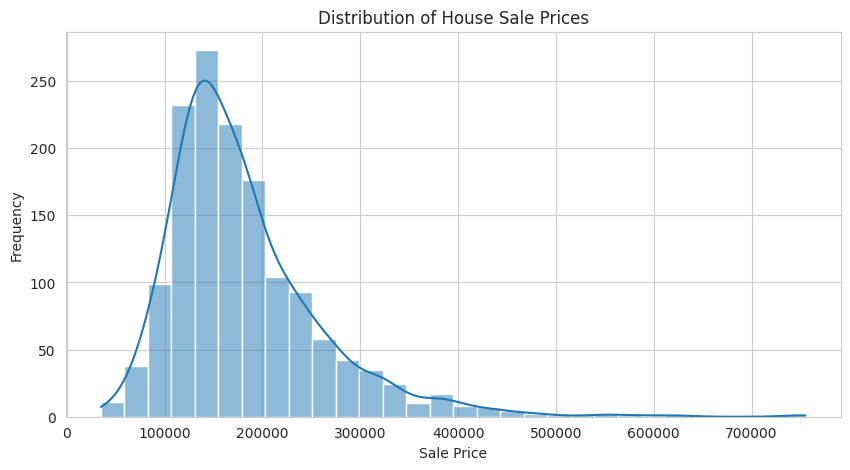

In [76]:

plt.figure(figsize=(10, 5))

sns.histplot(
    df["SalePrice"],
    kde=True,
    bins=30
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()


SalePrice Boxplot

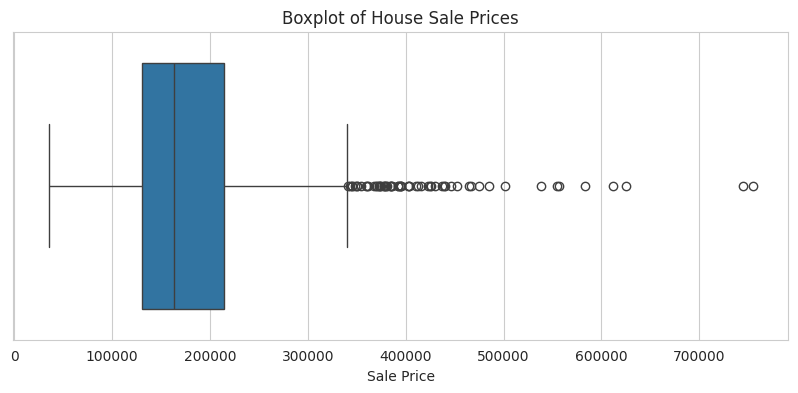

In [77]:

plt.figure(figsize=(10, 4))

sns.boxplot(x=df["SalePrice"])

plt.title("Boxplot of House Sale Prices")
plt.xlabel("Sale Price")

plt.show()


Log Transformation

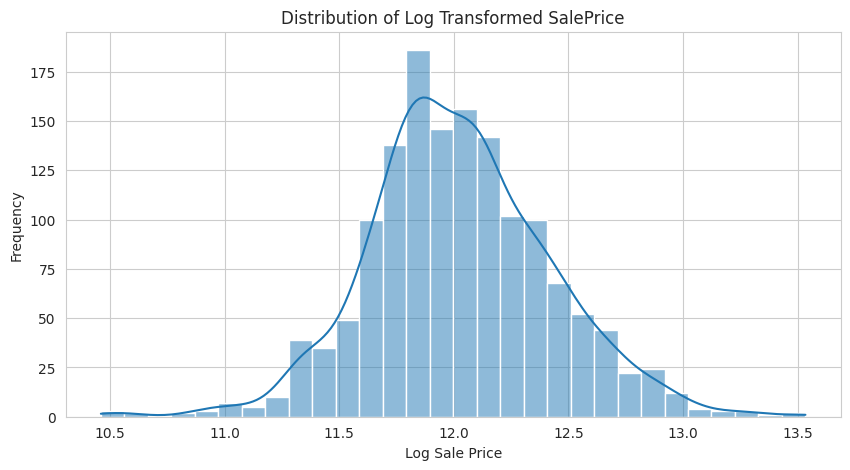

In [78]:

df["LogSalePrice"] = np.log(df["SalePrice"])

plt.figure(figsize=(10, 5))

sns.histplot(
    df["LogSalePrice"],
    kde=True,
    bins=30
)

plt.title("Distribution of Log Transformed SalePrice")
plt.xlabel("Log Sale Price")
plt.ylabel("Frequency")

plt.show()


Compare Skewness

In [79]:

original_skew = df["SalePrice"].skew()
log_skew = df["LogSalePrice"].skew()

print("Original SalePrice Skewness:", original_skew)
print("Log Transformed Skewness:", log_skew)


Original SalePrice Skewness: 1.8828757597682129
Log Transformed Skewness: 0.12133506220520406


Quality vs House Price

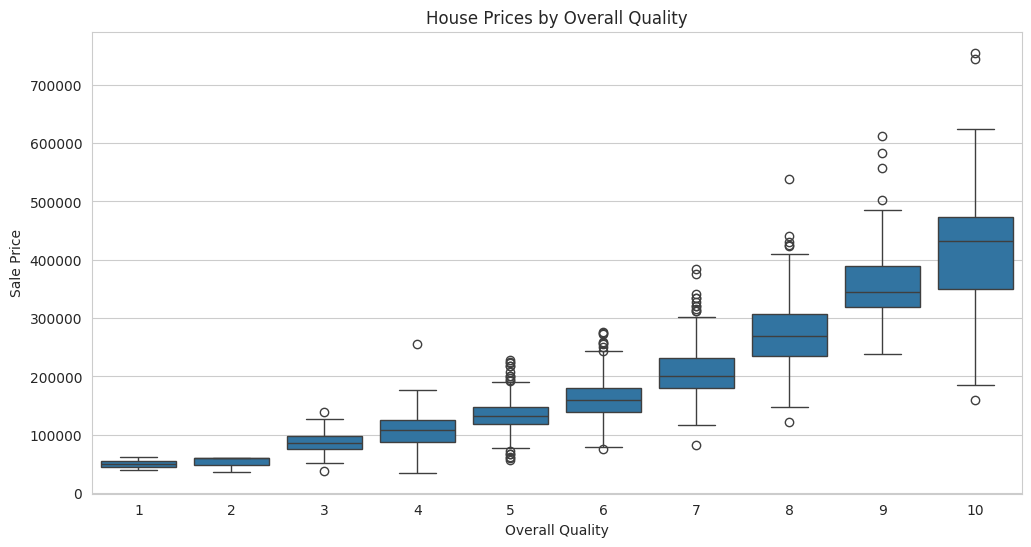

In [80]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    x="OverallQual",
    y="SalePrice",
    data=df
)

plt.title("House Prices by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()


Neighborhood vs House Price

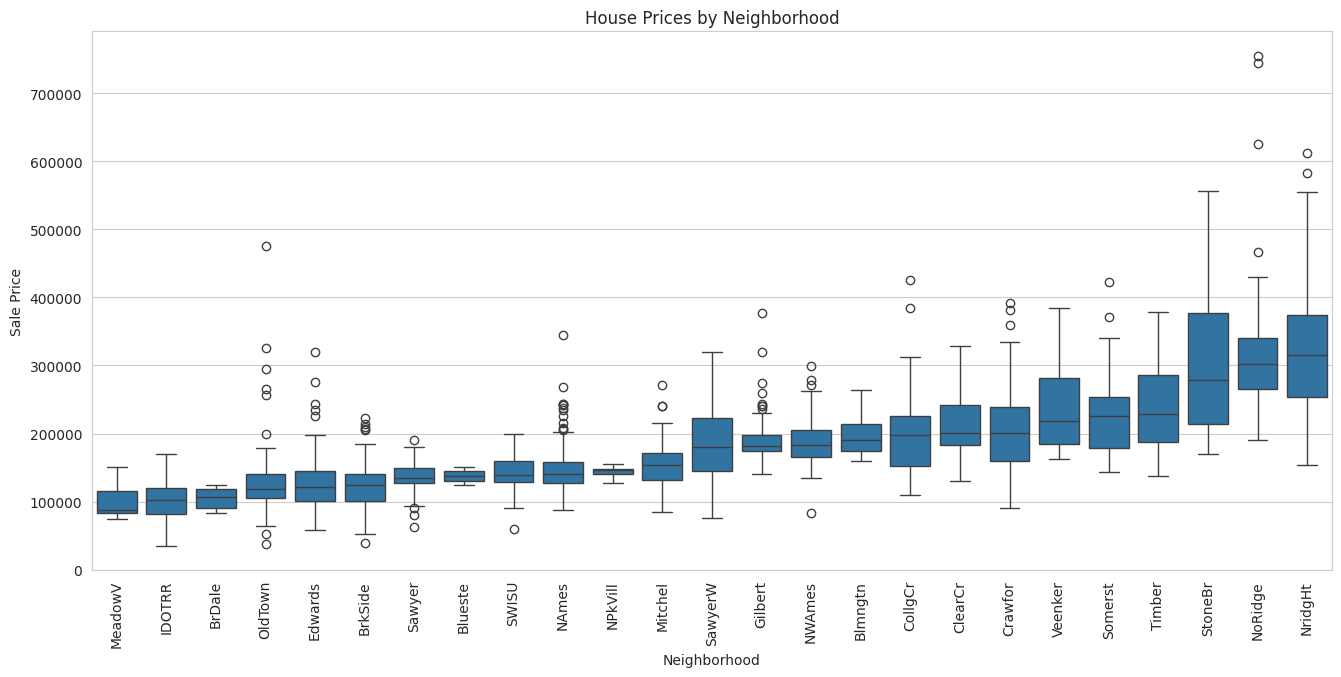

In [81]:

# Sort neighborhoods by median house price
neighborhood_order = (
    df.groupby("Neighborhood", observed=True)["SalePrice"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(16, 7))

sns.boxplot(
    x="Neighborhood",
    y="SalePrice",
    data=df,
    order=neighborhood_order
)

plt.title("House Prices by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")

plt.xticks(rotation=90)

plt.show()


Overall Quality Countplot

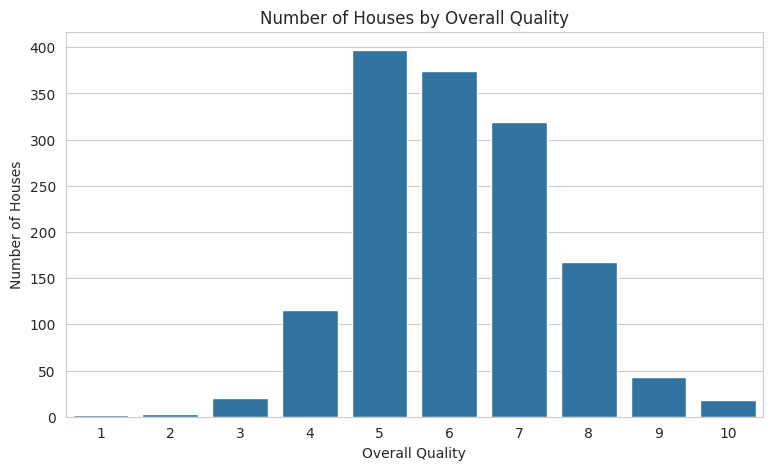

In [82]:

plt.figure(figsize=(9, 5))

sns.countplot(
    x="OverallQual",
    data=df
)

plt.title("Number of Houses by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Number of Houses")

plt.show()


HouseStyle Countplot

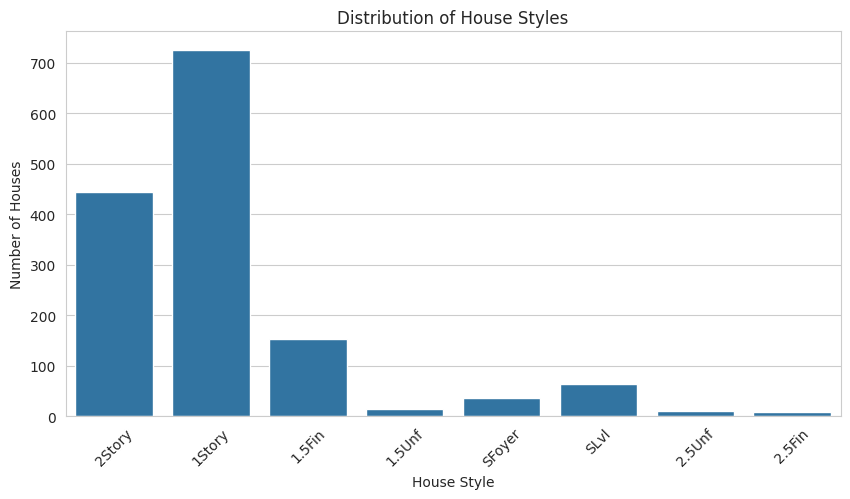

In [83]:

plt.figure(figsize=(10, 5))

sns.countplot(
    x="HouseStyle",
    data=df
)

plt.title("Distribution of House Styles")
plt.xlabel("House Style")
plt.ylabel("Number of Houses")

plt.xticks(rotation=45)

plt.show()


### Observations – Distribution Analysis

1. The SalePrice histogram helps us understand the distribution of house prices.
2. The boxplot shows the median, spread and potential outliers.
3. Log transformation helps reduce the right skewness of SalePrice.
4. The boxplot by OverallQual helps us understand the relationship between house quality and selling price.
5. The Neighborhood boxplot shows differences in house prices across neighbourhoods.
6. The OverallQual countplot shows the frequency of different quality ratings.
7. The HouseStyle countplot shows the distribution of different house styles.

**Conclusion:** Distribution analysis helps identify patterns, price variations, potential outliers and relationships between house prices and important features.

## 7. Correlation and Covariance Analysis

Correlation and covariance are statistical techniques used to understand the relationships between numerical variables.

In this step, we analyse how different house features are related to SalePrice and identify the features with the strongest correlations.

Covariance Matrix

In [84]:

# Select numerical columns
numeric_data = df.select_dtypes(include=np.number).drop(
    columns=["Id", "LogSalePrice"],
    errors="ignore"
)

# Calculate covariance matrix
cov_matrix = numeric_data.cov()

display(cov_matrix)


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
MSSubClass,1789.338306,-404.439075,-5.901742e+04,1.908771,-2.792117,3.558134e+01,35.439934,1.758378e+02,-1.347356e+03,-447.979166,...,-6.669453e+01,-1.709661e+01,-31.119180,-54.348569,-61.394007,14.076652,-161.243759,-1.553607,-1.202630,-2.832337e+05
LotFrontage,-404.439075,589.749169,8.199814e+04,8.673047,-1.573935,9.510848e+01,45.744675,8.712074e+02,2.635953e+03,187.215374,...,2.587889e+02,2.438681e+02,16.022614,48.936214,56.264418,194.586364,15.520479,0.735389,0.240700,7.124262e+05
LotArea,-59017.418634,81998.138404,9.962565e+07,1460.548271,-62.602871,4.289113e+03,2841.343594,1.884014e+05,9.746908e+05,179002.233638,...,2.148006e+05,5.606253e+04,-11188.088772,5976.210971,24020.024881,31148.209380,188508.749657,32.517342,-189.050203,2.092111e+08
OverallQual,1.908771,8.673047,1.460548e+03,1.912679,-0.141484,2.390622e+01,15.723417,1.030121e+02,1.511770e+02,-13.189617,...,4.141573e+01,2.829764e+01,-9.630806,1.231398,5.003537,3.620945,-21.548945,0.264785,-0.050229,8.690413e+04
OverallCond,-2.792117,-1.573935,-6.260287e+01,-0.141484,1.238322,-1.263671e+01,1.694152,-2.581896e+01,-2.346427e+01,7.221779,...,-4.649741e-01,-2.402762e+00,4.785160,0.832039,3.400819,-0.088745,37.970669,-0.010563,0.064953,-6.882739e+03
YearBuilt,35.581337,95.108483,4.289113e+03,23.906215,-12.636709,9.122154e+02,369.675456,1.725993e+03,3.437028e+03,-239.263730,...,8.513053e+02,3.775838e+02,-714.886948,27.763434,-84.815514,6.006353,-515.209195,1.012426,-0.546237,1.254637e+06
YearRemodAdd,35.439934,45.744675,2.841344e+03,15.723417,1.694152,3.696755e+02,426.232822,6.716764e+02,1.209533e+03,-225.669866,...,5.323509e+02,3.095486e+02,-244.692937,27.410061,-44.594964,4.835329,-105.358566,1.199517,0.980046,8.317079e+05
MasVnrArea,175.837842,871.207424,1.884014e+05,103.012054,-25.818956,1.725993e+03,671.676358,3.278497e+04,2.182760e+04,-2117.724160,...,3.626330e+03,1.503301e+03,-1218.999064,100.044636,622.125969,85.516034,-2685.666442,-2.915638,-1.973363,6.854858e+06
BsmtFinSF1,-1347.355751,2635.952669,9.746908e+05,151.176998,-23.464270,3.437028e+03,1209.532821,2.182760e+04,2.080255e+05,-3687.508609,...,1.167953e+04,3.377322e+03,-2851.840396,353.685020,1577.237193,2574.473738,808.155748,-19.393195,8.697797,1.400137e+07
BsmtFinSF2,-447.979166,187.215374,1.790022e+05,-13.189617,7.221779,-2.392637e+02,-225.669866,-2.117724e+03,-3.687509e+03,26023.907779,...,1.372874e+03,3.305446e+01,360.306240,-141.852290,799.374305,270.331980,395.351466,-6.634118,6.792848,-1.458175e+05


In [85]:

# Calculate Pearson correlation
corr_matrix = numeric_data.corr(method="pearson")

display(corr_matrix)


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
MSSubClass,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,-0.065649,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,0.049900,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,0.111170,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,-0.059119,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,0.040229,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,-0.049107,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,-0.067759,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,-0.072319,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,-0.050117,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420
BsmtFinSF2,-0.065649,0.049900,0.111170,-0.059119,0.040229,-0.049107,-0.067759,-0.072319,-0.050117,1.000000,...,0.067898,0.003093,0.036543,-0.029993,0.088871,0.041709,0.004940,-0.015211,0.031706,-0.011378


In [86]:

# Get correlation with SalePrice
saleprice_corr = corr_matrix["SalePrice"]

# Sort by absolute correlation
top_corr = saleprice_corr.drop("SalePrice").reindex(
    saleprice_corr.drop("SalePrice").abs().sort_values(
        ascending=False
    ).index
)

# Display top 10 features
print("Top 10 Features Correlated with SalePrice:")
display(top_corr.head(10).to_frame("Correlation"))


Top 10 Features Correlated with SalePrice:


,Correlation
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


In [87]:

# Select top 3 correlated features
top_3 = top_corr.head(3).index

for col in top_3:

    print("\nFeature:", col)

    print(
        "Correlation with SalePrice:",
        corr_matrix.loc[col, "SalePrice"]
    )

    print(
        "Covariance with SalePrice:",
        cov_matrix.loc[col, "SalePrice"]
    )



Feature: OverallQual
Correlation with SalePrice: 0.7909816005838053
Covariance with SalePrice: 86904.12583679946

Feature: GrLivArea
Correlation with SalePrice: 0.7086244776126515
Covariance with SalePrice: 29581866.743236575

Feature: GarageCars
Correlation with SalePrice: 0.6404091972583519
Covariance with SalePrice: 38020.18135897172


In [88]:
#Feature-to-Feature Correlation
print(
    "Correlation between GarageArea and GarageCars:",
    corr_matrix.loc["GarageArea", "GarageCars"]
)


Correlation between GarageArea and GarageCars: 0.882475414281462


In [89]:
#Spearman Correlation
spearman_corr = df[
    ["OverallQual", "SalePrice"]
].corr(method="spearman")

print("Spearman Correlation:")
display(spearman_corr)


Spearman Correlation:


,OverallQual,SalePrice
OverallQual,1.000000,0.809829
SalePrice,0.809829,1.000000


### Observations – Correlation and Covariance

1. Covariance helps identify whether two numerical variables move in the same or opposite directions.
2. Pearson correlation measures the strength and direction of a linear relationship.
3. The top 10 correlated features help identify important variables associated with SalePrice.
4. Correlation values range from -1 to +1, making them easier to compare.
5. GarageArea and GarageCars may have a positive relationship because larger garages can accommodate more vehicles.
6. Spearman correlation helps analyse the relationship between ordinal variables and house prices.

**Important:** Correlation does not imply causation. A strong correlation does not prove that one variable causes a change in another.

**Conclusion:** Correlation and covariance help us understand relationships between house features and identify variables strongly associated with house prices.

## 8. Scatter Plots and Pair Plots

Scatter plots help us understand the relationship between two numerical variables.

Pair plots help us visualise relationships between multiple numerical variables at the same time.

In this step, we analyse living area, basement area, construction year and house sale prices to identify patterns and unusual observations.

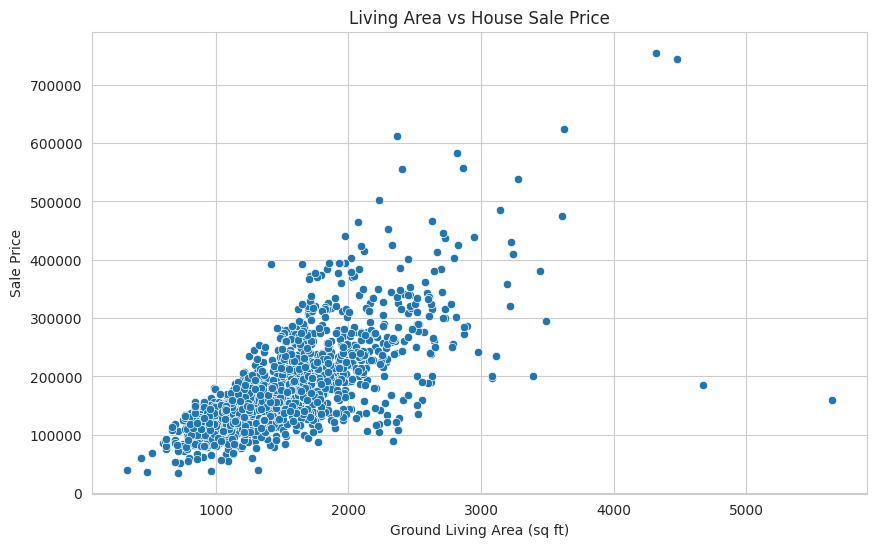

In [90]:
#Living Area vs Sale Price
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs House Sale Price")
plt.xlabel("Ground Living Area (sq ft)")
plt.ylabel("Sale Price")

plt.show()


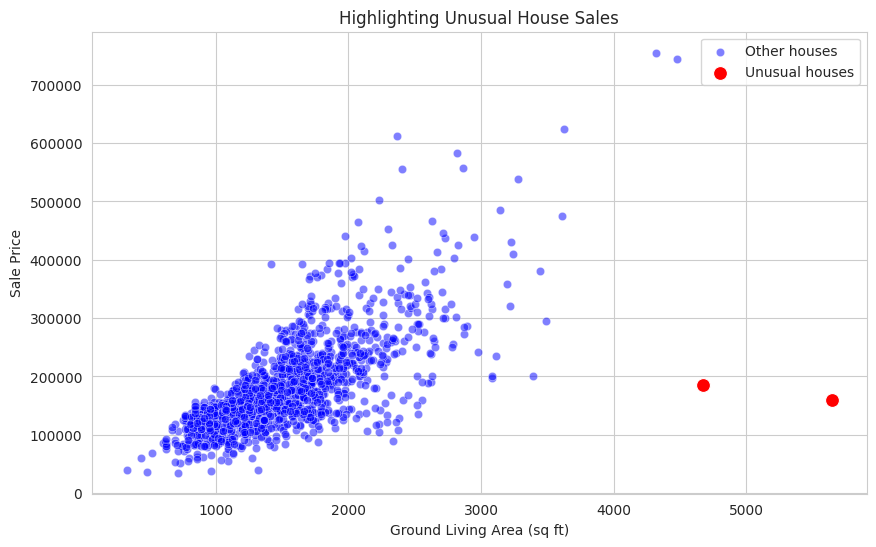

Number of unusual houses: 2


,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


In [91]:

# Identify unusual houses
unusual = df[
    (df["GrLivArea"] > 4000) &
    (df["SalePrice"] < 200000)
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    color="blue",
    alpha=0.5,
    label="Other houses"
)

sns.scatterplot(
    data=unusual,
    x="GrLivArea",
    y="SalePrice",
    color="red",
    s=100,
    label="Unusual houses"
)

plt.title("Highlighting Unusual House Sales")
plt.xlabel("Ground Living Area (sq ft)")
plt.ylabel("Sale Price")
plt.legend()

plt.show()

print("Number of unusual houses:", len(unusual))
display(unusual[["Id", "GrLivArea", "SalePrice"]])


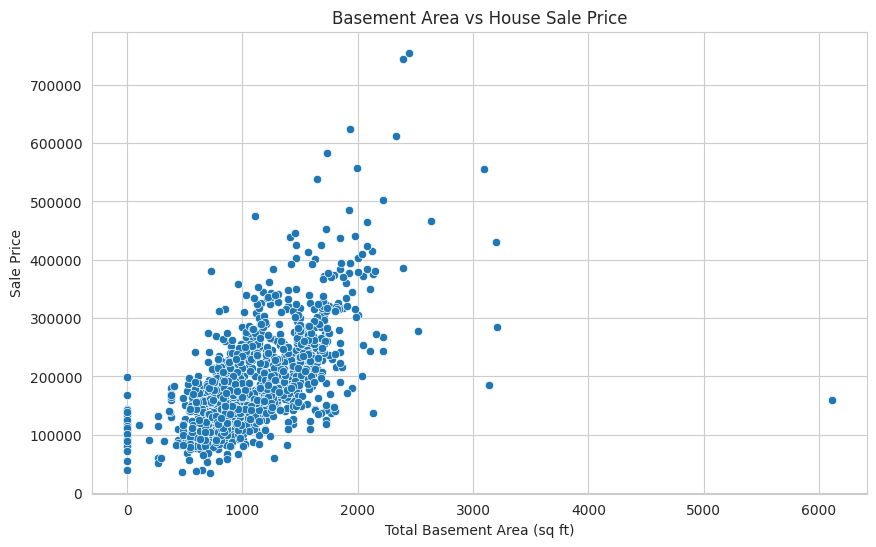

In [92]:
#Basement Area vs Sale Price
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="TotalBsmtSF",
    y="SalePrice"
)

plt.title("Basement Area vs House Sale Price")
plt.xlabel("Total Basement Area (sq ft)")
plt.ylabel("Sale Price")

plt.show()


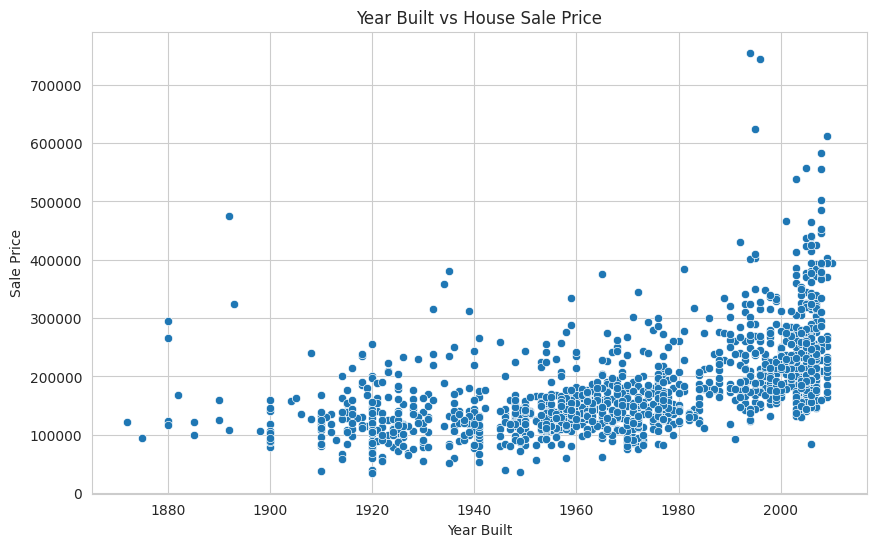

In [93]:
#Construction Year vs Sale Price
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="YearBuilt",
    y="SalePrice"
)

plt.title("Year Built vs House Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")

plt.show()


In [94]:
# selected columns
selected = [
    "SalePrice",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt"
]

pair_data = df[selected]

print("Selected columns:")
print(pair_data.head())


Selected columns:
   SalePrice  GrLivArea  TotalBsmtSF  GarageArea  YearBuilt
0     208500       1710          856         548       2003
1     181500       1262         1262         460       1976
2     223500       1786          920         608       2001
3     140000       1717          756         642       1915
4     250000       2198         1145         836       2000


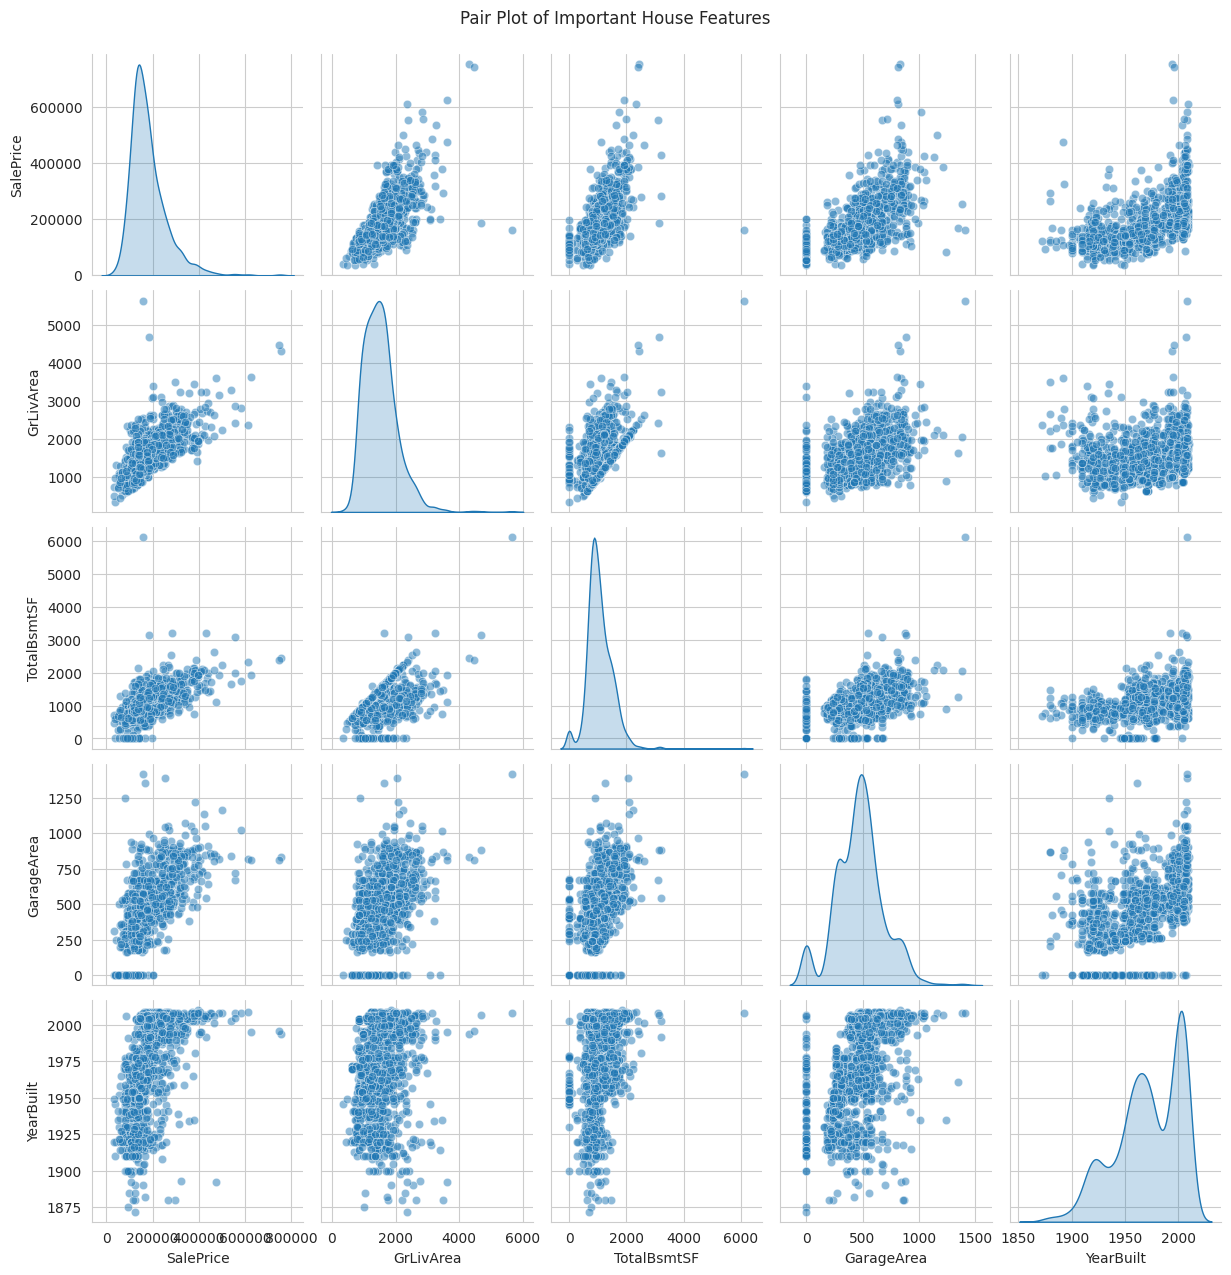

In [95]:
#generate pair plot
sns.pairplot(
    pair_data,
    diag_kind="kde",
    plot_kws={"alpha": 0.5}
)

plt.suptitle(
    "Pair Plot of Important House Features",
    y=1.02
)

plt.show()


### Observations – Scatter Plots and Pair Plots

1. The GrLivArea scatter plot helps analyse the relationship between living area and house prices.
2. The TotalBsmtSF scatter plot shows how basement area is related to selling prices.
3. The YearBuilt scatter plot helps examine the relationship between construction year and house prices.
4. Some houses with large living areas and comparatively low selling prices may be unusual observations.
5. The pair plot helps visualise relationships between multiple numerical features.
6. The diagonal KDE plots show the individual distributions of selected numerical variables.

**Conclusion:** Scatter plots and pair plots help identify relationships, trends and unusual observations in the housing dataset.

### Step 7: Correlation Heatmap

In this step, we will identify the 10 numerical features most strongly correlated with `SalePrice`. We will use these features to create a correlation heatmap and understand the relationships between them.

In [96]:
# Select numerical columns
numeric_data = df.select_dtypes(include=np.number).drop(
    columns=["Id", "LogSalePrice"], errors="ignore"
)

# Calculate correlation with SalePrice
correlation = numeric_data.corr()

# Find top 10 features correlated with SalePrice
top_corr = correlation["SalePrice"].drop("SalePrice")

top_10_features = (
    top_corr.abs()
    .sort_values(ascending=False)
    .head(10)
    .index.tolist()
)

print("Top 10 features correlated with SalePrice:")
print(top_10_features)

Top 10 features correlated with SalePrice:
['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd']


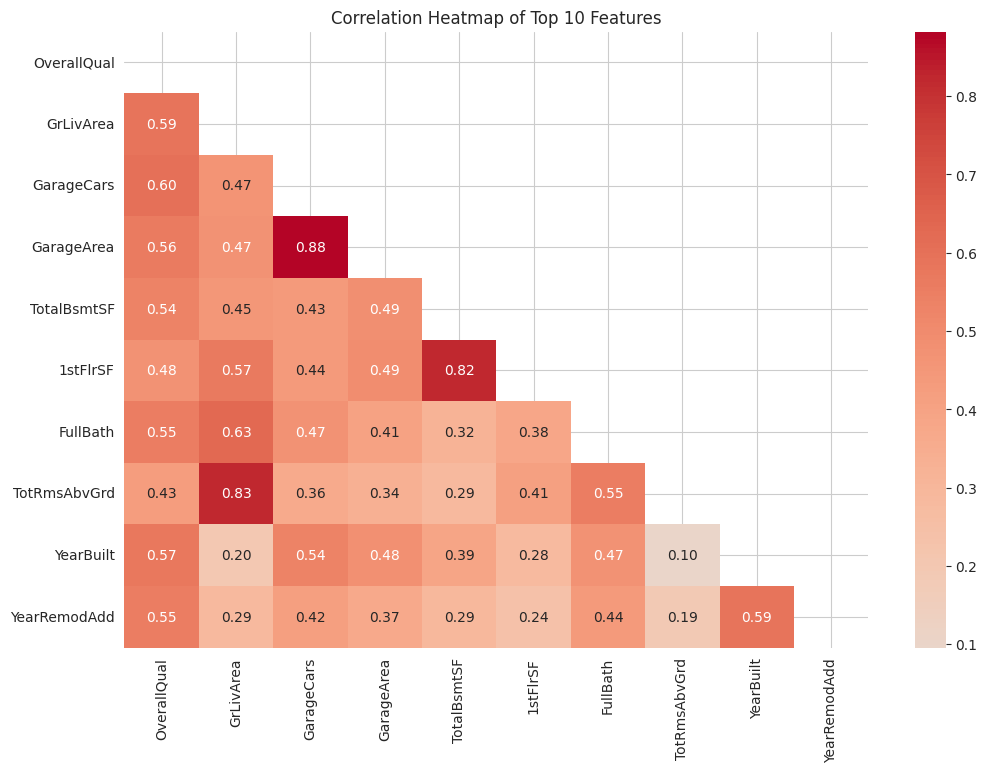

In [97]:
# Create correlation matrix for top 10 features
corr_top = numeric_data[top_10_features].corr()

# Create mask for upper triangle
mask = np.triu(np.ones_like(corr_top, dtype=bool))

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_top,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Top 10 Features")
plt.show()

### Observations

1. The heatmap shows the correlation between the 10 numerical features most strongly associated with `SalePrice`.
2. Features with correlation values closer to +1 have a stronger positive relationship.
3. Features with correlation values closer to -1 have a stronger negative relationship.
4. Some features may also be strongly correlated with each other.
5. This heatmap helps us understand relationships between numerical variables in the housing dataset.

#### 8.2 IQR Method

We will create a function that calculates Q1, Q3, and IQR. It will identify rows where the selected column contains values below the lower limit or above the upper limit.

In [98]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = series[(series < lower) | (series > upper)]

    return outliers

#### 8.3 Z-score Method

We will calculate the Z-score for each value. If the absolute Z-score is greater than 3, the value will be identified as an outlier.

In [99]:
def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()

    outliers = series[abs(z) > threshold]

    return outliers

#### 8.4 Comparison of IQR and Z-score

We will apply both methods to `GrLivArea` and `SalePrice`. We will compare the number of outliers detected by each method and count how many rows are common to both methods.

In [100]:
for col in ["GrLivArea", "SalePrice"]:

    a = iqr_outliers(df[col])
    b = zscore_outliers(df[col])

    print("Column:", col)
    print("IQR outliers:", len(a))
    print("Z-score outliers:", len(b))
    print("Common outliers:", len(set(a.index) & set(b.index)))
    print("-----------------------------")

Column: GrLivArea
IQR outliers: 31
Z-score outliers: 16
Common outliers: 16
-----------------------------
Column: SalePrice
IQR outliers: 61
Z-score outliers: 22
Common outliers: 22
-----------------------------


#### 8.5 Boxplots for Outlier Detection

We will create boxplots for `GrLivArea` and `SalePrice` to visually identify unusually high or low values.

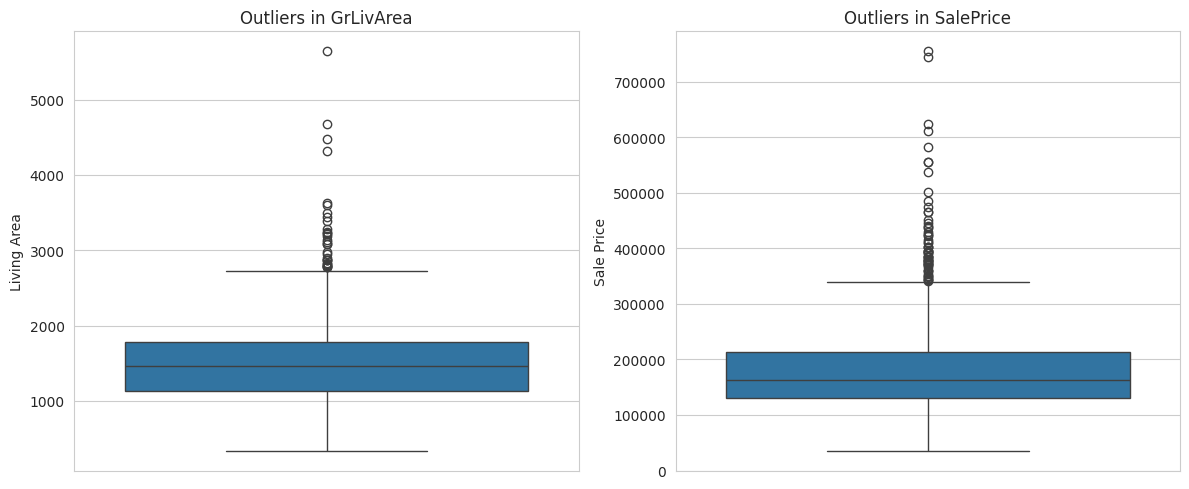

In [101]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["GrLivArea"])
plt.title("Outliers in GrLivArea")
plt.ylabel("Living Area")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["SalePrice"])
plt.title("Outliers in SalePrice")
plt.ylabel("Sale Price")

plt.tight_layout()
plt.show()

#### 8.6 Scatter Plot of Flagged Outliers

We will create a scatter plot of living area against sale price. The flagged outliers will be highlighted so that we can visually inspect unusual house sales.

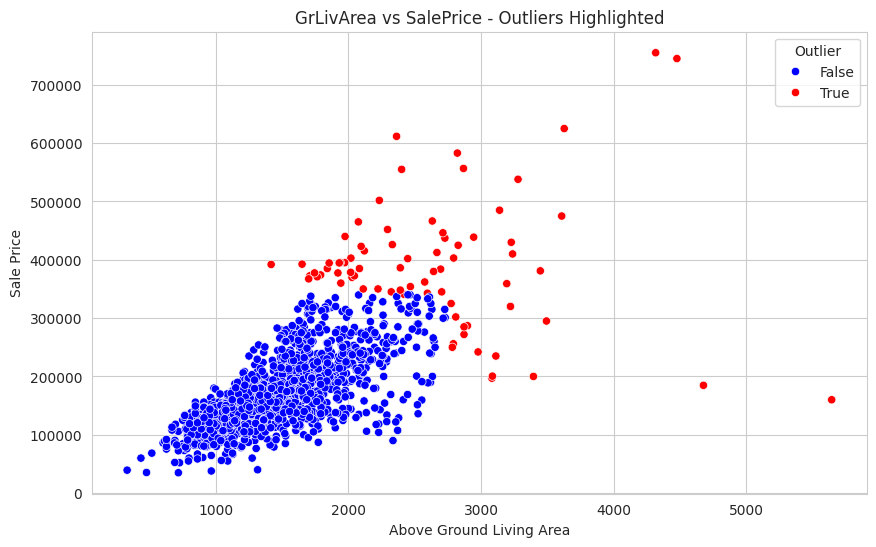

In [102]:
# Get outlier indexes from both methods
area_outliers = set(iqr_outliers(df["GrLivArea"]).index) | set(
    zscore_outliers(df["GrLivArea"]).index
)

price_outliers = set(iqr_outliers(df["SalePrice"]).index) | set(
    zscore_outliers(df["SalePrice"]).index
)

# Combine both sets
all_outliers = area_outliers | price_outliers

# Create a flag column
df["Outlier"] = df.index.isin(all_outliers)

# Plot scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="Outlier",
    palette={False: "blue", True: "red"}
)

plt.title("GrLivArea vs SalePrice - Outliers Highlighted")
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")
plt.show()

#### 8.7 Inspecting Outliers

We will display the details of flagged houses. This will help us decide whether they are incorrect records or genuine unusual sales.

In [103]:
outlier_details = df[df["Outlier"]][
    ["Id", "GrLivArea", "SalePrice", "OverallQual", "YearBuilt"]
]

display(outlier_details.sort_values("GrLivArea", ascending=False).head(20))

,Id,GrLivArea,SalePrice,OverallQual,YearBuilt
1298,1299,5642,160000,10,2008
523,524,4676,184750,10,2007
1182,1183,4476,745000,10,1996
691,692,4316,755000,10,1994
1169,1170,3627,625000,10,1995
185,186,3608,475000,10,1892
304,305,3493,295000,7,1880
1268,1269,3447,381000,8,1935
635,636,3395,200000,6,1914
769,770,3279,538000,8,2003


In [104]:
# Create a separate copy for further analysis
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)

Original dataset shape: (1460, 83)
Clean dataset shape: (1460, 83)


### Step 8: Outlier Detection — Observations

1. The IQR method identified ______ outliers in `GrLivArea`.
2. The Z-score method identified ______ outliers in `GrLivArea`.
3. The IQR method identified ______ outliers in `SalePrice`.
4. The Z-score method identified ______ outliers in `SalePrice`.
5. The scatter plot helped identify unusual house sales.
6. Outliers should be removed only when there is a valid reason, such as an incorrect value. Genuine unusual sales should be retained and documented.

**Interpretation:** The Z-score method can flag fewer points than IQR on a skewed variable because extreme values can affect the mean and standard deviation, making the Z-score threshold less sensitive to some unusual observations.

### Step 9: Data Quality Checks and Cleaning

In this step, we will examine the dataset for missing values, duplicate rows, incorrect data types, and invalid values. We will perform basic data-quality checks before creating the final analysis dashboard.

In [105]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (1460, 83)
Number of Rows: 1460
Number of Columns: 83


#### 9.2 Checking Duplicate Records

Duplicate records can affect statistical analysis. We will check whether any complete rows are repeated in the dataset.

In [106]:
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


#### 9.3 Checking Missing Values

Missing values occur when information is not available for a particular column. We will calculate the number and percentage of missing values in each column.

In [107]:
missing_count = df_clean.isnull().sum()

missing_percentage = (
    df_clean.isnull().sum() / len(df_clean)
) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

missing_table = missing_table[
    missing_table["Missing Count"] > 0
].sort_values(by="Missing Percentage", ascending=False)

display(missing_table)

,Missing Count,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


#### 9.4 Missing Values Visualization

We will create a bar chart to identify columns containing the highest number of missing values.

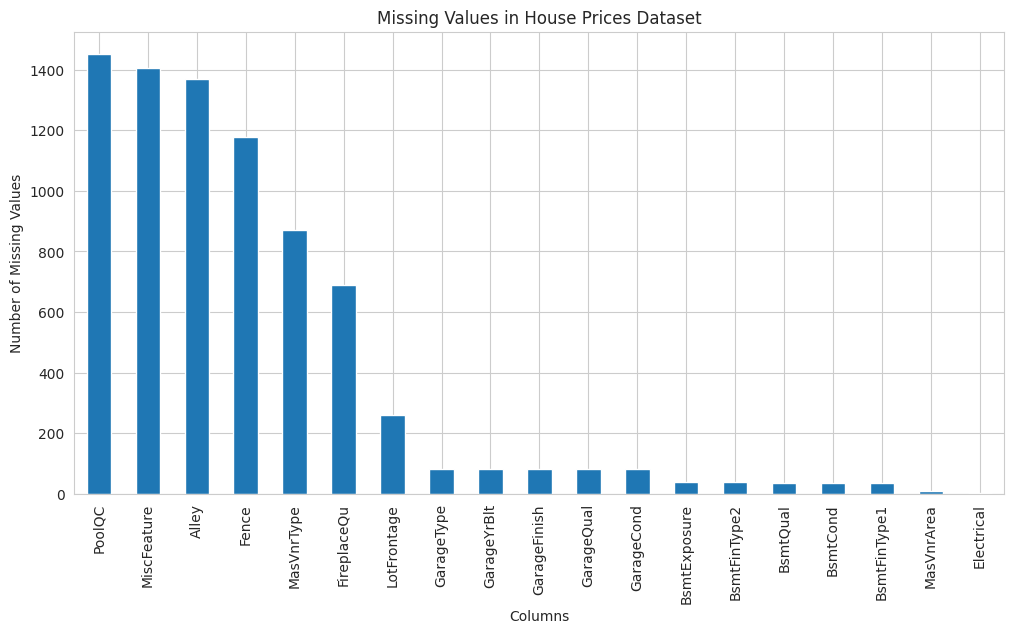

In [108]:
missing_values = df_clean.isnull().sum()
missing_values = missing_values[missing_values > 0]

plt.figure(figsize=(12, 6))

missing_values.sort_values(ascending=False).plot(kind="bar")

plt.title("Missing Values in House Prices Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=90)
plt.show()

In [109]:
# Check missing values in selected columns

check_columns = [
    "PoolQC",
    "GarageType",
    "FireplaceQu",
    "Alley",
    "MasVnrType"
]

for col in check_columns:
    if col in df_clean.columns:
        print(col, ":", df_clean[col].isnull().sum())

PoolQC : 1453
GarageType : 81
FireplaceQu : 690
Alley : 1369
MasVnrType : 872


#### 9.6 Checking Data Types

We will examine the data types of all columns to make sure numerical and categorical variables are stored appropriately.

In [110]:
display(df_clean.dtypes.to_frame("Data Type"))

,Data Type
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
...,...
SaleType,object
SaleCondition,object
SalePrice,int64
LogSalePrice,float64


#### 9.7 Checking Invalid Numerical Values

We will inspect important numerical columns for zero and negative values. Some zero values may be valid, such as houses with no basement area, so we will investigate rather than automatically remove them.

In [111]:
important_columns = [
    "SalePrice",
    "GrLivArea",
    "LotArea",
    "TotalBsmtSF",
    "GarageArea"
]

for col in important_columns:
    print("\n", col)
    print("Zero values:", (df_clean[col] == 0).sum())
    print("Negative values:", (df_clean[col] < 0).sum())


 SalePrice
Zero values: 0
Negative values: 0

 GrLivArea
Zero values: 0
Negative values: 0

 LotArea
Zero values: 0
Negative values: 0

 TotalBsmtSF
Zero values: 37
Negative values: 0

 GarageArea
Zero values: 81
Negative values: 0


In [112]:
# Keep a separate cleaned dataset
df_clean = df_clean.copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("Remaining duplicate rows:", df_clean.duplicated().sum())
print("Total missing values:", df_clean.isnull().sum().sum())

Original dataset shape: (1460, 83)
Cleaned dataset shape: (1460, 83)
Remaining duplicate rows: 0
Total missing values: 7829


### Step 9: Data Quality — Observations

1. Duplicate records were checked in the dataset.
2. Missing values were identified in several columns.
3. Some missing values indicate the absence of house features, such as a pool, garage, or fireplace.
4. Data types were examined to identify numerical and categorical columns.
5. Zero and negative values were checked in important numerical columns.
6. The cleaned dataset was created without unnecessarily deleting valid information.

**Conclusion:** Data quality checks help ensure that the dataset is suitable for further exploratory analysis.

# Final EDA Dashboard

The final dashboard presents the important findings from the Exploratory Data Analysis of the Ames Housing Dataset.

It includes:
1. Distribution of house sale prices.
2. Relationship between living area and sale price.
3. Average sale price by overall quality.
4. Correlation between important numerical features.

The dashboard helps us understand the major factors associated with house prices.

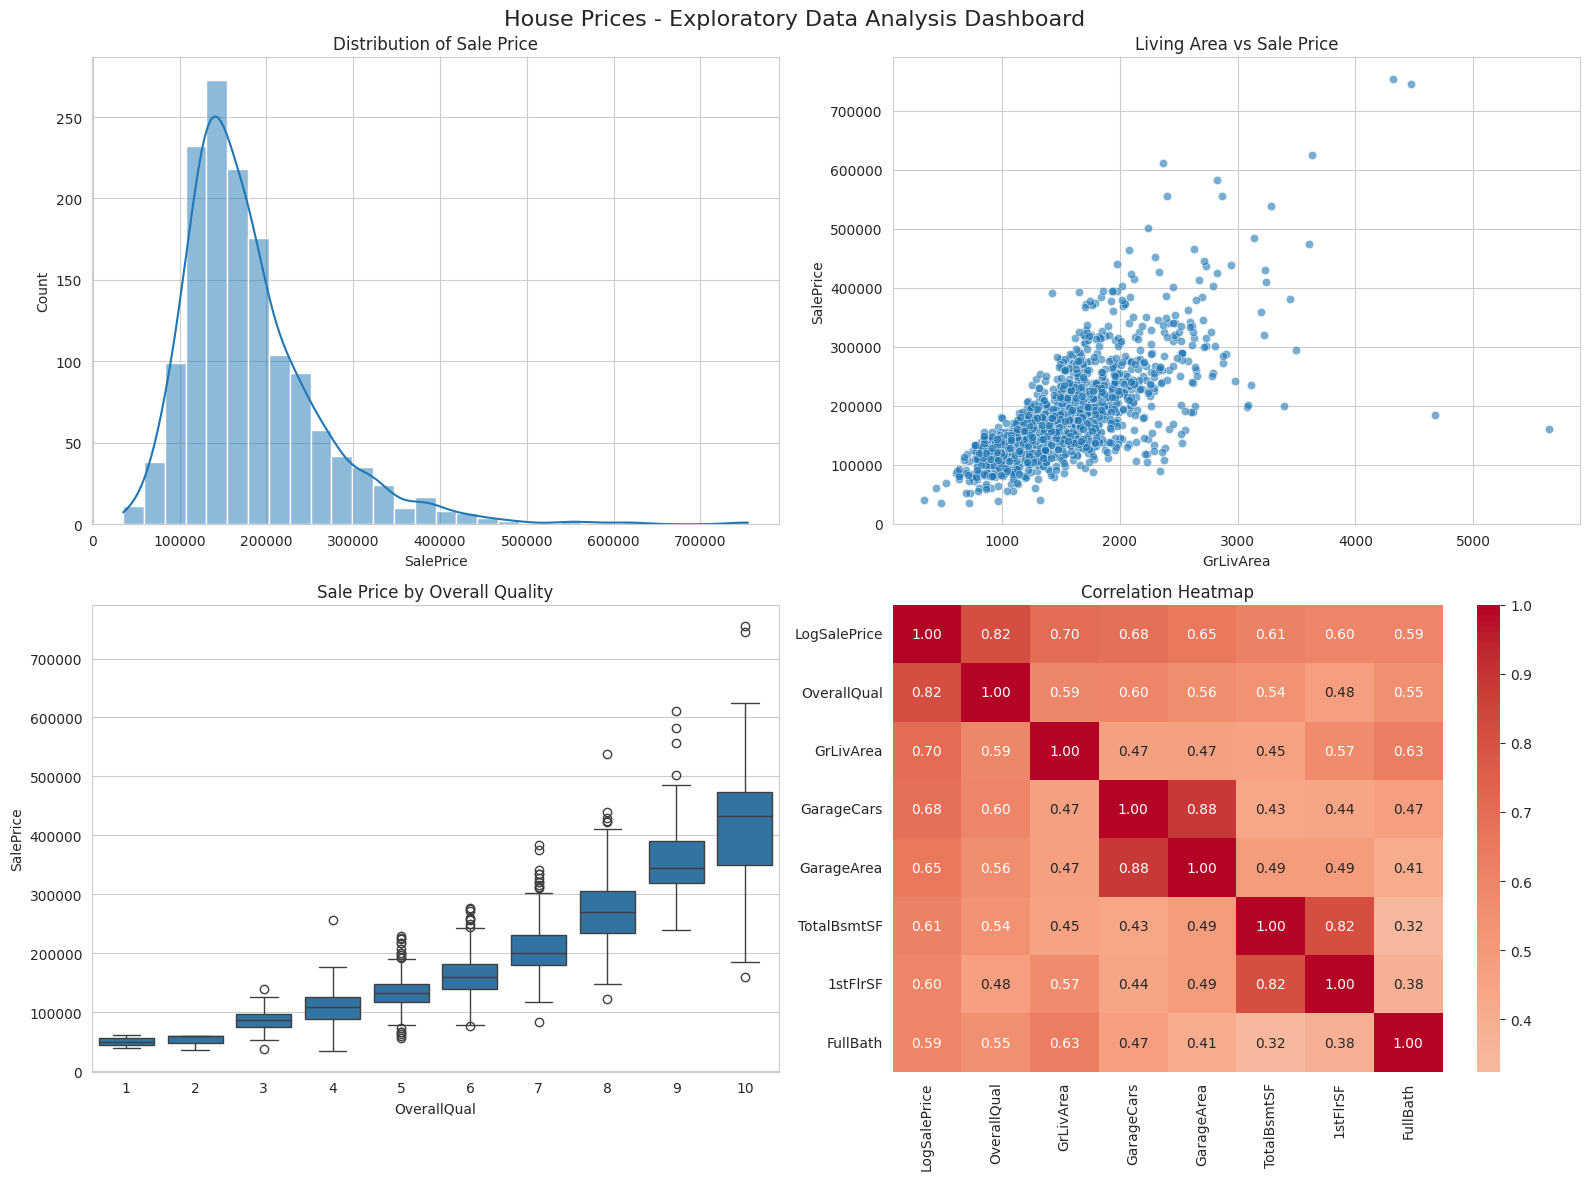

In [113]:
# Create a 2x2 dashboard

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. SalePrice Distribution
sns.histplot(
    data=df_clean,
    x="SalePrice",
    kde=True,
    bins=30,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Sale Price")

# 2. GrLivArea vs SalePrice
sns.scatterplot(
    data=df_clean,
    x="GrLivArea",
    y="SalePrice",
    alpha=0.6,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Living Area vs Sale Price")

# 3. SalePrice by OverallQual
sns.boxplot(
    data=df_clean,
    x="OverallQual",
    y="SalePrice",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Sale Price by Overall Quality")

# 4. Correlation Heatmap
dashboard_corr = df_clean.select_dtypes(include=np.number).corr()

top_features = (
    dashboard_corr["SalePrice"]
    .drop("SalePrice")
    .abs()
    .sort_values(ascending=False)
    .head(8)
    .index.tolist()
)

heatmap_corr = df_clean[top_features].corr()

sns.heatmap(
    heatmap_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Correlation Heatmap")

plt.suptitle(
    "House Prices - Exploratory Data Analysis Dashboard",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Key Findings

1. The SalePrice distribution was analyzed to understand the pricing pattern of houses.
2. Numerical analysis helped identify features associated with house prices.
3. OverallQual showed an important relationship with SalePrice.
4. GrLivArea helped us understand how living area relates to house prices.
5. Neighborhood analysis showed differences in house prices across locations.
6. Correlation analysis helped identify relationships between numerical variables.
7. IQR and Z-score methods were used to identify potential outliers.
8. Missing-value analysis showed that some missing values represent absent house features rather than incorrect data.

## Final Conclusion

Exploratory Data Analysis helped us understand the Ames Housing Dataset and identify important patterns in house prices.

The analysis showed that house quality, living area, and location are useful factors for understanding variations in sale prices. Data visualization, descriptive statistics, correlation analysis, and outlier detection helped reveal patterns and unusual observations.

Data cleaning and missing-value analysis also improved our understanding of the dataset.

This project demonstrates how Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn can be used to perform Exploratory Data Analysis effectively.

**No machine learning model was developed because this project focuses only on Exploratory Data Analysis.**

In [114]:
print("FINAL PROJECT SUMMARY")
print("-----------------------------")

print("Dataset Shape:", df_clean.shape)
print("Total Records:", len(df_clean))
print("Total Features:", len(df_clean.columns))

print("Average Sale Price:", round(df_clean["SalePrice"].mean(), 2))
print("Median Sale Price:", round(df_clean["SalePrice"].median(), 2))

print("Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())

print("-----------------------------")
print("EDA PROJECT COMPLETED!")

FINAL PROJECT SUMMARY
-----------------------------
Dataset Shape: (1460, 83)
Total Records: 1460
Total Features: 83
Average Sale Price: 180921.2
Median Sale Price: 163000.0
Missing Values: 7829
Duplicate Rows: 0
-----------------------------
EDA PROJECT COMPLETED!
